# Architecture Overview & Environment Setup

In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"

In [2]:
import os
import sys
import math

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [3]:
IMAGE_SIZE = 112
EMBEDDING_SIZE = 128
NUM_CLASSES = 5103

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Image size:", IMAGE_SIZE)
print("Embedding size:", EMBEDDING_SIZE)
print("Number of classes:", NUM_CLASSES)

Device: cuda
Image size: 112
Embedding size: 128
Number of classes: 5103


# MobileFaceNet Building Blocks

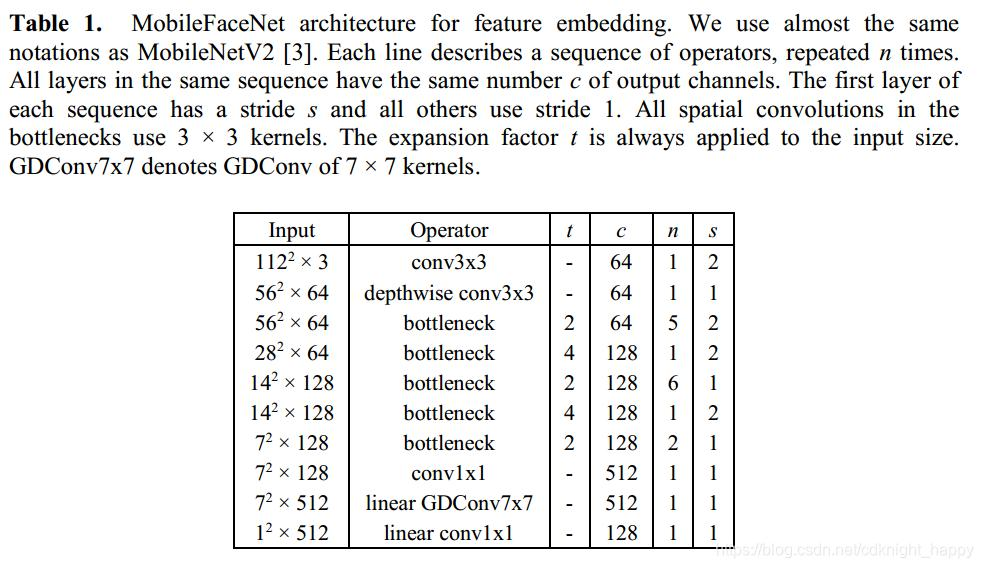

In [4]:
class Conv_block(nn.Module):

    def __init__(self, in_c, out_c, kernel_size, stride, padding, groups=1):

        super(Conv_block, self).__init__()

        self.conv = nn.Conv2d(
            in_c,
            out_c,
            kernel_size,
            stride,
            padding,
            groups=groups,
            bias=False
        )

        self.bn = nn.BatchNorm2d(out_c)
        self.prelu = nn.PReLU(out_c)

    def forward(self, x):

        x = self.conv(x)
        x = self.bn(x)
        x = self.prelu(x)

        return x

In [5]:
class Linear_block(nn.Module):

    def __init__(self, in_c, out_c, kernel_size, stride, padding, groups=1):

        super(Linear_block, self).__init__()

        self.conv = nn.Conv2d(
            in_c,
            out_c,
            kernel_size,
            stride,
            padding,
            groups=groups,
            bias=False
        )

        self.bn = nn.BatchNorm2d(out_c)

    def forward(self, x):

        x = self.conv(x)
        x = self.bn(x)

        return x

In [6]:
class Bottleneck(nn.Module):

    def __init__(self, in_c, out_c, expansion, stride):

        super(Bottleneck, self).__init__()

        mid_c = in_c * expansion

        self.use_residual = (stride == 1 and in_c == out_c)

        # 1. Expansion: 1x1 convolution
        self.conv1 = Conv_block(
            in_c=in_c,
            out_c=mid_c,
            kernel_size=1,
            stride=1,
            padding=0
        )

        # 2. Depthwise convolution: 3x3
        self.conv2 = Conv_block(
            in_c=mid_c,
            out_c=mid_c,
            kernel_size=3,
            stride=stride,
            padding=1,
            groups=mid_c
        )

        # 3. Linear projection: 1x1 convolution
        self.conv3 = Linear_block(
            in_c=mid_c,
            out_c=out_c,
            kernel_size=1,
            stride=1,
            padding=0
        )

    def forward(self, x):

        identity = x

        out = self.conv1(x)
        out = self.conv2(out)
        out = self.conv3(out)

        if self.use_residual:
            out = out + identity

        return out

In [7]:
sample = torch.randn(2, 64, 56, 56)

conv = Conv_block(64, 128, 3, 1, 1)
linear = Linear_block(128, 64, 1, 1, 0)
bottleneck = Bottleneck(64, 64, expansion=2, stride=1)

x = conv(sample)
print("Conv block:", x.shape)

x = linear(x)
print("Linear block:", x.shape)

x = bottleneck(sample)
print("Bottleneck:", x.shape)

Conv block: torch.Size([2, 128, 56, 56])
Linear block: torch.Size([2, 64, 56, 56])
Bottleneck: torch.Size([2, 64, 56, 56])


# Building MobileFaceNet Stages

In [8]:
def _make_stage(in_c, out_c, expansion, num_blocks, stride):

    layers = []

    for i in range(num_blocks):

        block_stride = stride if i == 0 else 1

        block_in_c = in_c if i == 0 else out_c

        layers.append(
            Bottleneck(
                in_c=block_in_c,
                out_c=out_c,
                expansion=expansion,
                stride=block_stride
            )
        )

    return nn.Sequential(*layers)

In [9]:
# Test the stage 

stage = _make_stage(
    in_c=64,
    out_c=64,
    expansion=2,
    num_blocks=3,
    stride=1
)

sample = torch.randn(2, 64, 56, 56)

output = stage(sample)

print("Input shape:", sample.shape)
print("Output shape:", output.shape)
print("Number of bottlenecks:", len(stage))

Input shape: torch.Size([2, 64, 56, 56])
Output shape: torch.Size([2, 64, 56, 56])
Number of bottlenecks: 3


In [10]:
# Test Spatial Downsampling 

downsample_stage = _make_stage(
    in_c=64,
    out_c=128,
    expansion=2,
    num_blocks=3,
    stride=2
)

sample = torch.randn(2, 64, 56, 56)

output = downsample_stage(sample)

print("Input shape:", sample.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 64, 56, 56])
Output shape: torch.Size([2, 128, 28, 28])


# Complete MobileFaceNet Architecture

In [11]:
class MobileFaceNet(nn.Module):

    def __init__(self, embedding_size=128):

        super(MobileFaceNet, self).__init__()

        # Initial convolution layers
        self.conv1 = Conv_block(
            in_c=3, out_c=64,
            kernel_size=3, stride=2, padding=1
        )

        self.conv2_dw = Conv_block(
            in_c=64, out_c=64,
            kernel_size=3, stride=1, padding=1,
            groups=64
        )

        # Bottleneck stages
        self.stage1 = _make_stage(
            in_c=64, out_c=64,
            expansion=2, num_blocks=5, stride=2
        )

        self.stage2 = _make_stage(
            in_c=64, out_c=128,
            expansion=4, num_blocks=1, stride=2
        )

        self.stage3 = _make_stage(
            in_c=128, out_c=128,
            expansion=2, num_blocks=6, stride=1
        )

        self.stage4 = _make_stage(
            in_c=128, out_c=128,
            expansion=4, num_blocks=1, stride=2
        )

        self.stage5 = _make_stage(
            in_c=128, out_c=128,
            expansion=2, num_blocks=2, stride=1
        )

        # Final convolution
        self.conv6 = Conv_block(
            in_c=128, out_c=512,
            kernel_size=1, stride=1, padding=0
        )

        self.conv7_dw = Linear_block(
            in_c=512, out_c=512,
            kernel_size=7, stride=1, padding=0,
            groups=512
        )

        # Embedding layer
        self.linear = nn.Linear(
            in_features=512,
            out_features=embedding_size,
            bias=False
        )

        self.bn = nn.BatchNorm1d(embedding_size)

    def forward(self, x):

        x = self.conv1(x)
        x = self.conv2_dw(x)

        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.stage5(x)

        x = self.conv6(x)
        x = self.conv7_dw(x)

        x = torch.flatten(x, start_dim=1)

        x = self.linear(x)
        x = self.bn(x)

        return x

In [12]:
model = MobileFaceNet(
    embedding_size=EMBEDDING_SIZE
).to(DEVICE)

sample_input = torch.randn(
    2, 3, IMAGE_SIZE, IMAGE_SIZE
).to(DEVICE)

with torch.no_grad():
    embeddings = model(sample_input)

print("Input shape:", sample_input.shape)
print("Embedding shape:", embeddings.shape)
print("Device:", embeddings.device)

Input shape: torch.Size([2, 3, 112, 112])
Embedding shape: torch.Size([2, 128])
Device: cuda:0


In [13]:
total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

Total parameters: 1,003,136
Trainable parameters: 1,003,136


# ArcFace Implementation

In [14]:
class ArcFace(nn.Module):

    def __init__(
        self,
        embedding_size,
        num_classes,
        scale=64.0,
        margin=0.5
    ):

        super(ArcFace, self).__init__()

        self.embedding_size = embedding_size
        self.num_classes = num_classes
        self.scale = scale
        self.margin = margin

        self.weight = nn.Parameter(
            torch.empty(num_classes, embedding_size)
        )

        nn.init.xavier_uniform_(self.weight)

        self.cos_m = math.cos(margin)
        self.sin_m = math.sin(margin)

        self.threshold = math.cos(math.pi - margin)
        self.mm = math.sin(math.pi - margin) * margin

    def forward(self, embeddings, labels):

        # Normalize embeddings and class weights
        embeddings = F.normalize(embeddings, p=2, dim=1)
        weight = F.normalize(self.weight, p=2, dim=1)

        # Calculate cosine similarity
        cosine = F.linear(embeddings, weight)

        # Calculate sine(theta)
        sine = torch.sqrt(
            torch.clamp(1.0 - cosine.pow(2), min=1e-7)
        )

        # Calculate cos(theta + margin)
        phi = cosine * self.cos_m - sine * self.sin_m

        # Apply threshold correction
        phi = torch.where(
            cosine > self.threshold,
            phi,
            cosine - self.mm
        )

        # Apply margin only to target identity
        one_hot = torch.zeros_like(cosine)

        one_hot.scatter_(
            1,
            labels.view(-1, 1),
            1.0
        )

        output = (
            one_hot * phi +
            (1.0 - one_hot) * cosine
        )

        # Apply scaling
        output *= self.scale

        return output

In [15]:
# Test ArcFace 

arcface = ArcFace(
    embedding_size=EMBEDDING_SIZE,
    num_classes=NUM_CLASSES
).to(DEVICE)

sample_embeddings = torch.randn(4, EMBEDDING_SIZE).to(DEVICE)

sample_labels = torch.tensor(
    [0, 100, 250, 1529],
    dtype=torch.long
).to(DEVICE)

logits = arcface(
    sample_embeddings,
    sample_labels
)

print("Embedding shape:", sample_embeddings.shape)
print("Labels shape:", sample_labels.shape)
print("ArcFace output shape:", logits.shape)

Embedding shape: torch.Size([4, 128])
Labels shape: torch.Size([4])
ArcFace output shape: torch.Size([4, 5103])


In [16]:
criterion = nn.CrossEntropyLoss()

loss = criterion(logits, sample_labels)

print("ArcFace loss:", loss.item())

ArcFace loss: 50.53529739379883


# Complete Model Integration

In [17]:
class FaceRecognitionModel(nn.Module):

    def __init__(
        self,
        embedding_size=128,
        num_classes=5103
    ):

        super(FaceRecognitionModel, self).__init__()

        self.backbone = MobileFaceNet(
            embedding_size=embedding_size
        )

        self.arcface = ArcFace(
            embedding_size=embedding_size,
            num_classes=num_classes
        )

    def forward(self, images, labels=None):

        embeddings = self.backbone(images)

        if labels is None:
            return embeddings

        logits = self.arcface(embeddings, labels)

        return logits, embeddings

In [18]:
model = FaceRecognitionModel(
    embedding_size=EMBEDDING_SIZE,
    num_classes=NUM_CLASSES
).to(DEVICE)

print(model)

FaceRecognitionModel(
  (backbone): MobileFaceNet(
    (conv1): Conv_block(
      (conv): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (prelu): PReLU(num_parameters=64)
    )
    (conv2_dw): Conv_block(
      (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (prelu): PReLU(num_parameters=64)
    )
    (stage1): Sequential(
      (0): Bottleneck(
        (conv1): Conv_block(
          (conv): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (prelu): PReLU(num_parameters=128)
        )
        (conv2): Conv_block(
          (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), 

In [19]:
sample_images = torch.randn(
    4, 3, IMAGE_SIZE, IMAGE_SIZE
).to(DEVICE)

sample_labels = torch.tensor(
    [0, 100, 250, 1529],
    dtype=torch.long
).to(DEVICE)

model.train()

logits, embeddings = model(
    sample_images,
    sample_labels
)

print("Input:", sample_images.shape)
print("Embeddings:", embeddings.shape)
print("Logits:", logits.shape)

Input: torch.Size([4, 3, 112, 112])
Embeddings: torch.Size([4, 128])
Logits: torch.Size([4, 5103])


In [20]:
model.eval()

with torch.no_grad():

    embeddings = model(sample_images)

print("Inference embeddings:", embeddings.shape)

Inference embeddings: torch.Size([4, 128])


# Model Analysis and Verification

In [21]:
total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

Total parameters: 1,656,320
Trainable parameters: 1,656,320


In [22]:
backbone_params = sum(
    parameter.numel()
    for parameter in model.backbone.parameters()
)

arcface_params = sum(
    parameter.numel()
    for parameter in model.arcface.parameters()
)

print("MobileFaceNet parameters:", f"{backbone_params:,}")
print("ArcFace parameters:", f"{arcface_params:,}")
print("Combined parameters:", f"{backbone_params + arcface_params:,}")

MobileFaceNet parameters: 1,003,136
ArcFace parameters: 653,184
Combined parameters: 1,656,320


In [23]:
model.train()
model.zero_grad(set_to_none=True)

sample_images = torch.randn(
    4, 3, IMAGE_SIZE, IMAGE_SIZE
).to(DEVICE)

sample_labels = torch.tensor(
    [0, 100, 250, 1529],
    dtype=torch.long
).to(DEVICE)

logits, embeddings = model(sample_images, sample_labels)

criterion = nn.CrossEntropyLoss()
loss = criterion(logits, sample_labels)

loss.backward()

print("Loss:", loss.item())

Loss: 54.901187896728516


# Save Model Architecture

In [32]:
%%writefile ../src/mobilefacenet.py

import torch
import torch.nn as nn


# --------------------------------------------------
# 1. Convolution Block
# --------------------------------------------------

class Conv_block(nn.Module):

    def __init__(self, in_c, out_c, kernel_size, stride, padding, groups=1):

        super(Conv_block, self).__init__()

        self.conv = nn.Conv2d(
            in_channels=in_c,
            out_channels=out_c,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            groups=groups,
            bias=False
        )

        self.bn = nn.BatchNorm2d(out_c)
        self.prelu = nn.PReLU(out_c)

    def forward(self, x):

        x = self.conv(x)
        x = self.bn(x)
        x = self.prelu(x)

        return x


# --------------------------------------------------
# 2. Linear Block
# --------------------------------------------------

class Linear_block(nn.Module):

    def __init__(self, in_c, out_c, kernel_size, stride, padding, groups=1):

        super(Linear_block, self).__init__()

        self.conv = nn.Conv2d(
            in_channels=in_c,
            out_channels=out_c,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            groups=groups,
            bias=False
        )

        self.bn = nn.BatchNorm2d(out_c)

    def forward(self, x):

        x = self.conv(x)
        x = self.bn(x)

        return x


# --------------------------------------------------
# 3. Bottleneck Block
# --------------------------------------------------

class Bottleneck(nn.Module):

    def __init__(self, in_c, out_c, expansion, stride):

        super(Bottleneck, self).__init__()

        mid_c = in_c * expansion

        self.use_residual = (stride == 1 and in_c == out_c)

        self.expand = Conv_block(
            in_c=in_c,
            out_c=mid_c,
            kernel_size=1,
            stride=1,
            padding=0
        )

        self.depthwise = Conv_block(
            in_c=mid_c,
            out_c=mid_c,
            kernel_size=3,
            stride=stride,
            padding=1,
            groups=mid_c
        )

        self.project = Linear_block(
            in_c=mid_c,
            out_c=out_c,
            kernel_size=1,
            stride=1,
            padding=0
        )

    def forward(self, x):

        identity = x

        out = self.expand(x)
        out = self.depthwise(out)
        out = self.project(out)

        if self.use_residual:
            out = out + identity

        return out


# --------------------------------------------------
# 4. Stage Creation
# --------------------------------------------------

def _make_stage(in_c, out_c, expansion, num_blocks, stride):

    layers = []

    for i in range(num_blocks):

        block_stride = stride if i == 0 else 1
        block_in_c = in_c if i == 0 else out_c

        layers.append(
            Bottleneck(
                in_c=block_in_c,
                out_c=out_c,
                expansion=expansion,
                stride=block_stride
            )
        )

    return nn.Sequential(*layers)


# --------------------------------------------------
# 5. MobileFaceNet Architecture
# --------------------------------------------------

class MobileFaceNet(nn.Module):

    def __init__(self, embedding_size=128):

        super(MobileFaceNet, self).__init__()

        # Initial convolution
        self.conv1 = Conv_block(
            in_c=3,
            out_c=64,
            kernel_size=3,
            stride=2,
            padding=1
        )

        # Initial depthwise convolution
        self.conv2 = Conv_block(
            in_c=64,
            out_c=64,
            kernel_size=3,
            stride=1,
            padding=1,
            groups=64
        )

        # Bottleneck stages
        self.stage1 = _make_stage(
            in_c=64,
            out_c=64,
            expansion=2,
            num_blocks=5,
            stride=2
        )

        self.stage2 = _make_stage(
            in_c=64,
            out_c=128,
            expansion=4,
            num_blocks=1,
            stride=2
        )

        self.stage3 = _make_stage(
            in_c=128,
            out_c=128,
            expansion=2,
            num_blocks=6,
            stride=1
        )

        self.stage4 = _make_stage(
            in_c=128,
            out_c=128,
            expansion=4,
            num_blocks=1,
            stride=2
        )

        self.stage5 = _make_stage(
            in_c=128,
            out_c=128,
            expansion=2,
            num_blocks=2,
            stride=1
        )

        # Final convolution
        self.conv6 = Conv_block(
            in_c=128,
            out_c=512,
            kernel_size=1,
            stride=1,
            padding=0
        )

        # Final depthwise convolution
        self.conv7 = Conv_block(
            in_c=512,
            out_c=512,
            kernel_size=7,
            stride=1,
            padding=0,
            groups=512
        )

        # Final linear convolution
        self.conv8 = Linear_block(
            in_c=512,
            out_c=embedding_size,
            kernel_size=1,
            stride=1,
            padding=0
        )

    def forward(self, x):

        x = self.conv1(x)
        x = self.conv2(x)

        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.stage5(x)

        x = self.conv6(x)
        x = self.conv7(x)
        x = self.conv8(x)

        x = torch.flatten(x, start_dim=1)

        return x


Overwriting ../src/mobilefacenet.py


In [25]:
%%writefile ../src/arcface.py

import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class ArcFace(nn.Module):

    def __init__(
        self,
        embedding_size,
        num_classes,
        scale=64.0,
        margin=0.5
    ):

        super(ArcFace, self).__init__()

        self.embedding_size = embedding_size
        self.num_classes = num_classes
        self.scale = scale
        self.margin = margin

        self.weight = nn.Parameter(
            torch.empty(num_classes, embedding_size)
        )

        nn.init.xavier_uniform_(self.weight)

        self.cos_m = math.cos(margin)
        self.sin_m = math.sin(margin)

        self.threshold = math.cos(math.pi - margin)
        self.mm = math.sin(math.pi - margin) * margin

    def forward(self, embeddings, labels):

        embeddings = F.normalize(embeddings, p=2, dim=1)
        weight = F.normalize(self.weight, p=2, dim=1)

        cosine = F.linear(embeddings, weight)

        sine = torch.sqrt(
            torch.clamp(1.0 - cosine.pow(2), min=1e-7)
        )

        phi = cosine * self.cos_m - sine * self.sin_m

        phi = torch.where(
            cosine > self.threshold,
            phi,
            cosine - self.mm
        )

        one_hot = torch.zeros_like(cosine)

        one_hot.scatter_(
            1,
            labels.view(-1, 1),
            1.0
        )

        output = (
            one_hot * phi +
            (1.0 - one_hot) * cosine
        )

        output *= self.scale

        return output

Writing ../src/arcface.py


In [26]:
%%writefile ../src/model.py

import torch.nn as nn

from .mobilefacenet import MobileFaceNet
from .arcface import ArcFace


class FaceRecognitionModel(nn.Module):

    def __init__(
        self,
        embedding_size=128,
        num_classes=5103
    ):

        super(FaceRecognitionModel, self).__init__()

        self.backbone = MobileFaceNet(
            embedding_size=embedding_size
        )

        self.arcface = ArcFace(
            embedding_size=embedding_size,
            num_classes=num_classes
        )

    def forward(self, images, labels=None):

        embeddings = self.backbone(images)

        if labels is None:
            return embeddings

        logits = self.arcface(embeddings, labels)

        return logits, embeddings

Writing ../src/model.py


In [27]:
%%writefile ../src/__init__.py

from .dataset import CelebADataset
from .transforms import get_train_transforms, get_eval_transforms

from .mobilefacenet import MobileFaceNet
from .arcface import ArcFace
from .model import FaceRecognitionModel

Overwriting ../src/__init__.py


In [28]:
import sys

sys.path.insert(0, str(PROJECT_ROOT))

from src import (
    MobileFaceNet,
    ArcFace,
    FaceRecognitionModel
)

print("All model modules imported successfully!")

All model modules imported successfully!


In [29]:
saved_model = FaceRecognitionModel(
    embedding_size=128,
    num_classes=5103
).to(DEVICE)

sample_images = torch.randn(
    2, 3, 112, 112
).to(DEVICE)

sample_labels = torch.tensor(
    [0, 1529],
    dtype=torch.long
).to(DEVICE)

saved_model.eval()

with torch.no_grad():

    embeddings = saved_model(sample_images)

print("Saved model output:", embeddings.shape)

Saved model output: torch.Size([2, 128])
